# Augmentation playground (tutorial — nothing here is exported to `src/`)

Interactive view of what the training pipeline actually does to your images/masks:

1. **Batch-level augs** (`apply_batch_augs` from `train.py`, issue #17): mosaic / mixup / cutmix /
   copy_paste, YOLO-style pick-one — exactly what `train_one_epoch` applies per training batch.
2. **Sample-level stack** (`get_train_transforms`): RandomCrop, Affine, GridDistortion,
   brightness/contrast, noise, blur, boundary_blur — the per-image Albumentations pipeline.

**To use your own data:** edit `IMAGE_PATHS` / `MASK_PATHS` in the config cell (mask = same stem
or your own list, binary `{0,255}` or `{0,1}`). With no paths, a synthetic demo dataset is
generated so the notebook runs end-to-end anywhere.

Mosaic needs a batch of ≥ 4 — if you give fewer images, the batch is padded with jittered
copies of yours (so donors differ). Nothing here is exported; copy cells you like into real
notebooks.

In [1]:
# config — EDIT THESE to point at your own data
IMAGE_PATHS = []   # e.g. ['/data/lot1/img_001.png', '/data/lot1/img_002.png', ...]
MASK_PATHS = []    # e.g. ['/data/lot1/mask_001.png', ...]  (same order as images)

N_SHOW = 4          # samples shown per figure
PAD_TO = 8          # batch is padded to this many samples (mosaic needs >= 4)
PICKONE_BATCHES = 6 # how many virtual training batches to show for pick-one sampling

# realistic recipe, same knobs as configs/train.yaml -> augment.batch.*
BATCH_AUGS = {'mosaic': 0.10, 'mixup': 0.05, 'cutmix': 0.0, 'copy_paste': 0.10, 'copy_paste_mode': 'flip'}

import sys
sys.path.insert(0, '../src')

In [2]:
# build the batch: your images, or a synthetic demo dataset (blobs on a textured background)
import cv2, numpy as np, torch, random
from segmentation_tools_pt.masks import binarize
from segmentation_tools_pt.train import (pick_batch_aug, apply_batch_augs,
    apply_mixup_batch, apply_cutmix_batch, apply_mosaic_batch, apply_copy_paste_batch)

def _synthetic_pair(rng):
    "One synthetic X-ray-like image + defect mask."
    H = W = 256
    base = rng.integers(60, 90, (H, W), dtype=np.uint8)
    xx, yy = np.meshgrid(np.arange(W), np.arange(H))
    for _ in range(rng.integers(2, 5)):
        cx, cy, r = rng.integers(0, W), rng.integers(0, H), rng.integers(20, 60)
        base = np.maximum(base, (90 * np.exp(-((xx-cx)**2 + (yy-cy)**2) / (2*r*r))).astype(np.uint8))
    img = cv2.GaussianBlur(base, (5, 5), 1.5)
    img = np.clip(img.astype(np.int16) + rng.normal(0, 6, (H, W)).astype(np.int16), 0, 255).astype(np.uint8)
    mask = np.zeros((H, W), np.uint8)
    for _ in range(rng.integers(2, 4)):
        cx, cy, r = rng.integers(30, W-30), rng.integers(30, H-30), rng.integers(8, 22)
        cv2.circle(mask, (cx, cy), r, 255, -1)
    return img, mask

rng = np.random.default_rng(0)
if IMAGE_PATHS and MASK_PATHS:
    assert len(IMAGE_PATHS) == len(MASK_PATHS), 'need one mask per image'
    imgs = [cv2.imread(str(p), cv2.IMREAD_GRAYSCALE) for p in IMAGE_PATHS]
    msks = [binarize(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)) for p in MASK_PATHS]
    assert all(i is not None for i in imgs), 'an image path failed to load'
    assert all(m is not None for m in msks), 'a mask path failed to load'
    src = list(zip(imgs, msks))
else:
    print('No paths given -> synthetic demo data (edit IMAGE_PATHS / MASK_PATHS above)')
    src = [_synthetic_pair(rng) for _ in range(4)]

H, W = src[0][0].shape
src = [(cv2.resize(i, (W, H)) if i.shape != (H, W) else i,
        cv2.resize(m, (W, H), interpolation=cv2.INTER_NEAREST) if m.shape != (H, W) else m)
       for i, m in src]

# pad the pool to PAD_TO with jittered copies so mosaic donors differ
pool = list(src)
while len(pool) < PAD_TO:
    i, m = src[len(pool) % len(src)]
    fac = float(rng.uniform(0.7, 1.3))
    pool.append((np.clip(i.astype(np.float32) * fac, 0, 255).astype(np.uint8), m))

images = torch.stack([torch.from_numpy(i.astype(np.float32)) for i, _ in pool]).unsqueeze(1)  # (B,1,H,W)
targets = torch.stack([torch.from_numpy(m.astype(np.float32)) for _, m in pool]).unsqueeze(1)
print(f'batch: images {tuple(images.shape)}  targets {tuple(targets.shape)}  (values 0-255, unnormalized on purpose)')

No paths given -> synthetic demo data (edit IMAGE_PATHS / MASK_PATHS above)
batch: images (8, 1, 256, 256)  targets (8, 1, 256, 256)  (values 0-255, unnormalized on purpose)


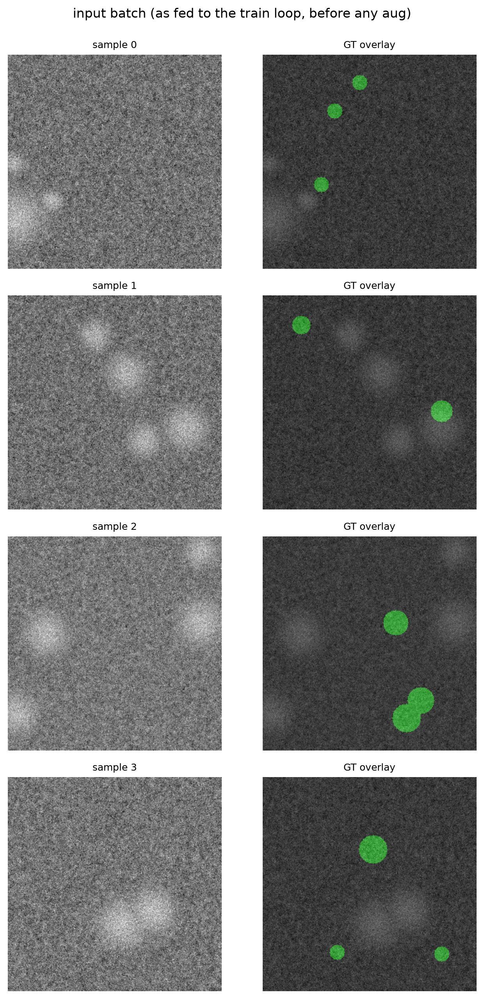

In [3]:
# viewer: rows = samples, cols = image | GT overlay (green = defect)
import matplotlib.pyplot as plt
from segmentation_tools_pt.visualize import overlay_gt_only

def _disp(x):
    x = x.detach().cpu().numpy()
    return x[0] if x.ndim == 3 else x

def show_batch(im, tg, title='', n=N_SHOW):
    n = min(n, im.shape[0])
    fig, axes = plt.subplots(n, 2, figsize=(7, 3.2 * n), squeeze=False)
    for r in range(n):
        axes[r][0].imshow(_disp(im[r]), cmap='gray'); axes[r][0].set_title(f'sample {r}', fontsize=9); axes[r][0].set_axis_off()
        overlay_gt_only(im[r], tg[r], ax=axes[r][1]); axes[r][1].set_title('GT overlay', fontsize=9)
    fig.suptitle(title, y=1.0 if n < 4 else 0.995)
    fig.tight_layout(); plt.show()

show_batch(images, targets, 'input batch (as fed to the train loop, before any aug)')

## Each batch-aug type, forced on (prob = 1.0)

Training never stacks them — each type is shown alone here so you can judge its effect.

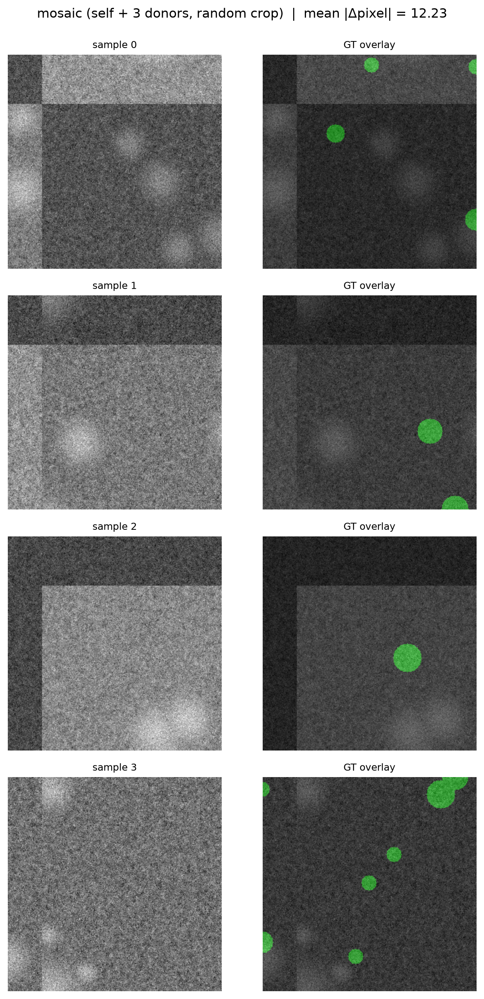

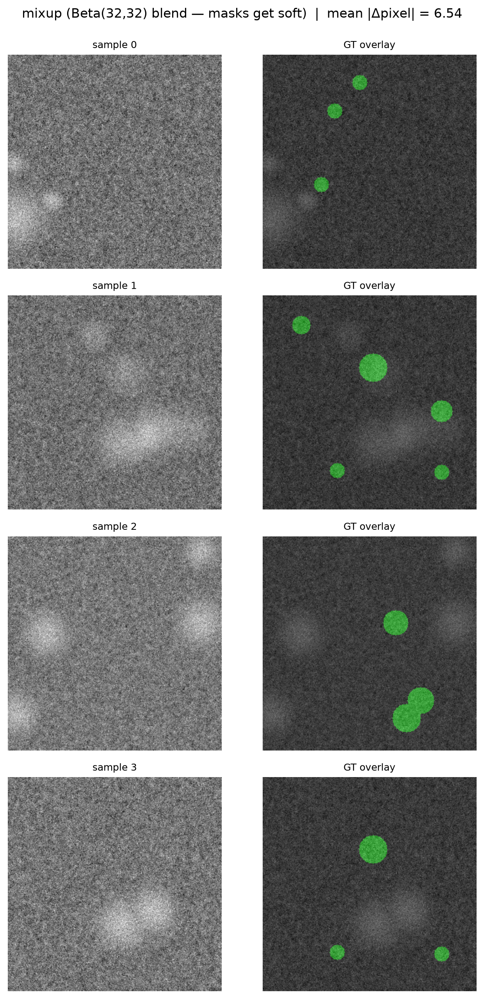

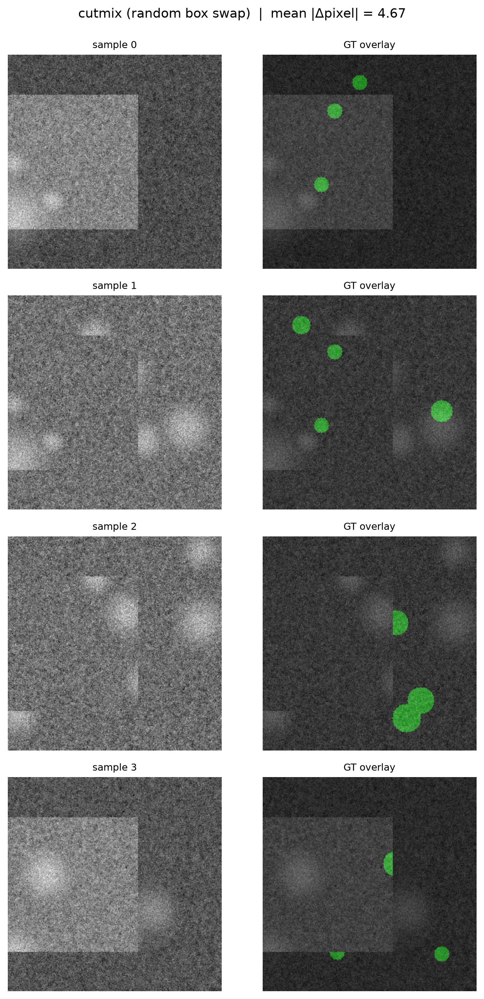

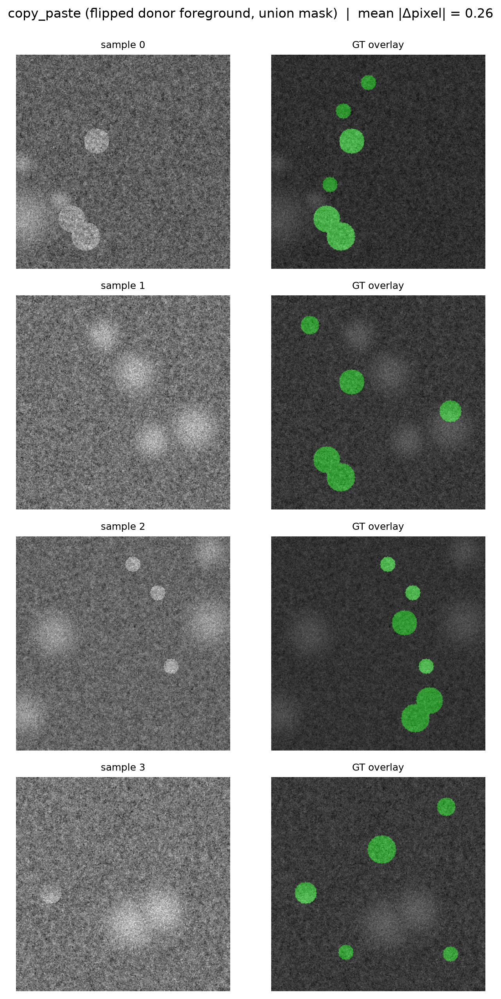

In [4]:
rng = random.Random(0)
for name, fn in [('mosaic (self + 3 donors, random crop)', apply_mosaic_batch),
                 ('mixup (Beta(32,32) blend — masks get soft)', apply_mixup_batch),
                 ('cutmix (random box swap)', apply_cutmix_batch),
                 ('copy_paste (flipped donor foreground, union mask)', apply_copy_paste_batch)]:
    im2, tg2 = fn(images, targets, rng=rng)
    changed = float((im2 - images).abs().mean())
    show_batch(im2, tg2, f'{name}  |  mean |Δpixel| = {changed:.2f}')

## Realistic pick-one sampling (what training actually sees)

Each "batch" below is one training step with `BATCH_AUGS` (the same probabilities you'd set in
`train.yaml`). Most batches get **no** batch aug at all — the title shows what was picked.

pick-one tally over virtual batches: {None: 2, 'mosaic': 3, 'copy_paste': 1}


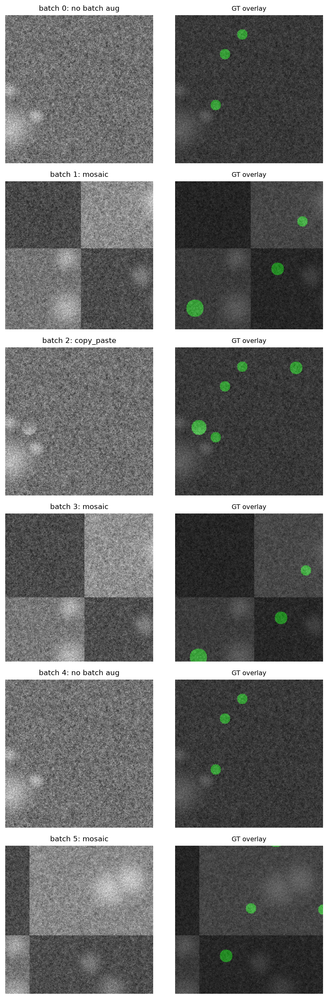

In [5]:
rng = random.Random(42)
fig, axes = plt.subplots(PICKONE_BATCHES, 2, figsize=(7, 3.2 * PICKONE_BATCHES), squeeze=False)
picked = {}
for r in range(PICKONE_BATCHES):
    im2, tg2, name = apply_batch_augs(images, targets, BATCH_AUGS, rng=rng)
    picked[name] = picked.get(name, 0) + 1
    axes[r][0].imshow(_disp(im2[0]), cmap='gray'); axes[r][0].set_axis_off()
    axes[r][0].set_title(f'batch {r}: {name or "no batch aug"}', fontsize=10)
    overlay_gt_only(im2[0], tg2[0], ax=axes[r][1]); axes[r][1].set_axis_off(); axes[r][1].set_title('GT overlay', fontsize=9)
fig.tight_layout(); plt.show()
print('pick-one tally over virtual batches:', picked)

## Bonus: the sample-level Albumentations stack (per-image, inside the DataLoader)

This is the *other* augmentation layer — `get_train_transforms` (RandomCrop, small Affine,
GridDistortion, brightness/contrast, noise, blur, `boundary_blur`). Applied to one of your
images a few times:

/home/hasan-spark/workspace/projects/git_data/segmentation_tools_pt_sanitized/.venv/lib/python3.12/site-packages/albumentations/check_version.py:147: UserWarning: Error fetching version info <urlopen error [Errno 104] Connection reset by peer>
  data = fetch_version_info()


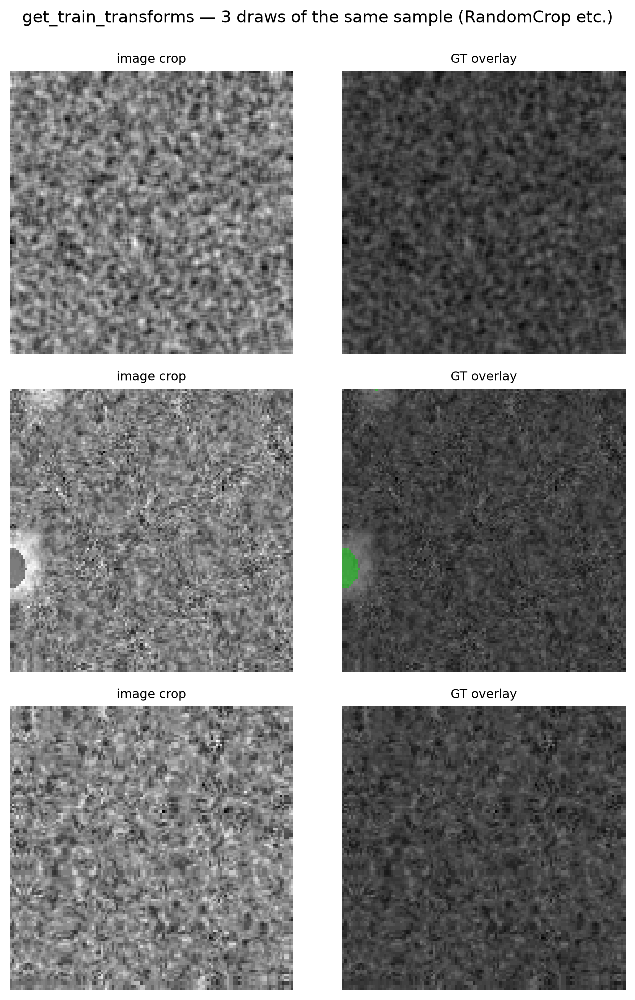

In [6]:
from segmentation_tools_pt.transforms import get_train_transforms

t = get_train_transforms(crop_size=min(H, W) // 2, mean=(0.0,), std=(255.0,),
                         flips=False, boundary_blur={'p': 1.0})
fig, axes = plt.subplots(3, 2, figsize=(7, 10), squeeze=False)
for r in range(3):
    out = t(image=pool[0][0], mask=pool[0][1])
    axes[r][0].imshow(out['image'][0], cmap='gray'); axes[r][0].set_axis_off(); axes[r][0].set_title('image crop', fontsize=9)
    overlay_gt_only(out['image'], out['mask'], ax=axes[r][1]); axes[r][1].set_title('GT overlay', fontsize=9)
fig.suptitle('get_train_transforms — 3 draws of the same sample (RandomCrop etc.)', y=0.995)
fig.tight_layout(); plt.show()